In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

plt.rcParams['figure.figsize'] = (8, 5)

In [2]:
df = pd.read_csv('Wholesale customers data.csv')

print(df.shape)
print(df.columns.tolist())
print("Valores ausentes:", df.isna().sum().sum())
df.head()

(440, 8)
['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
Valores ausentes: 0


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
externos = df[['Channel', 'Region']]              
gastos = df.drop(columns=['Channel', 'Region'])  

gastos.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [ ]:
estat = gastos.describe().T          
estat['assimetria'] = gastos.skew()  
estat

,count,mean,std,min,25%,50%,75%,max,assimetria
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0,2.561323
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0,4.053755
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0,3.587429
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0,5.907986
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0,3.631851
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0,11.151586


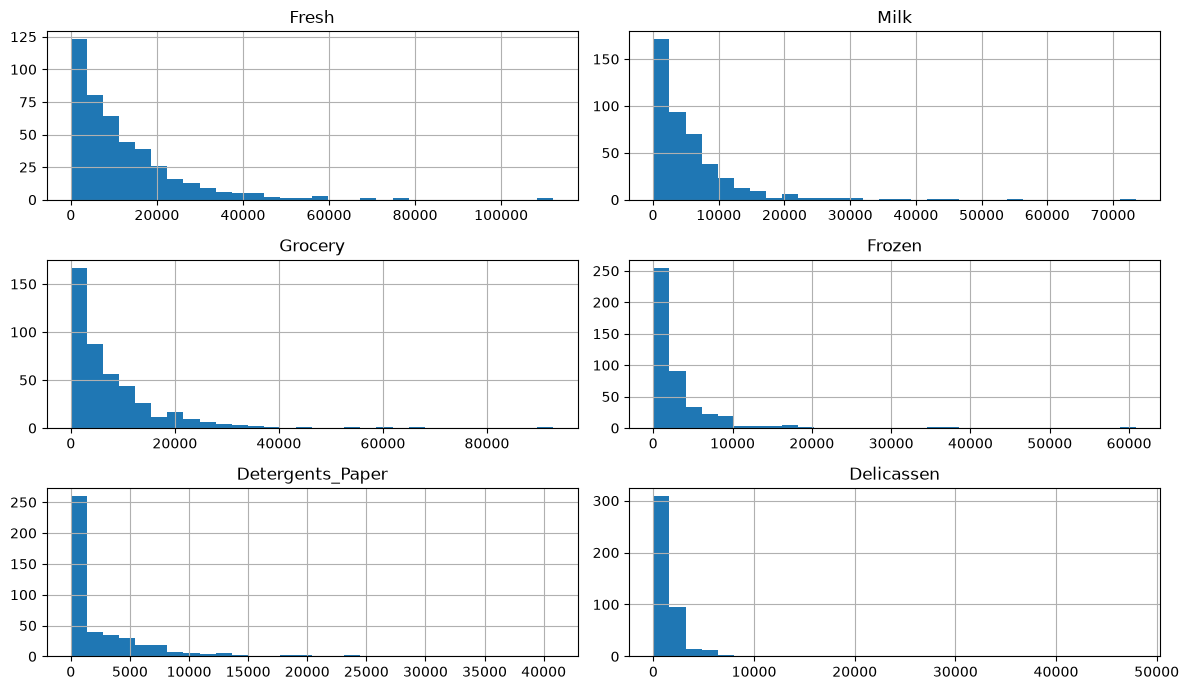

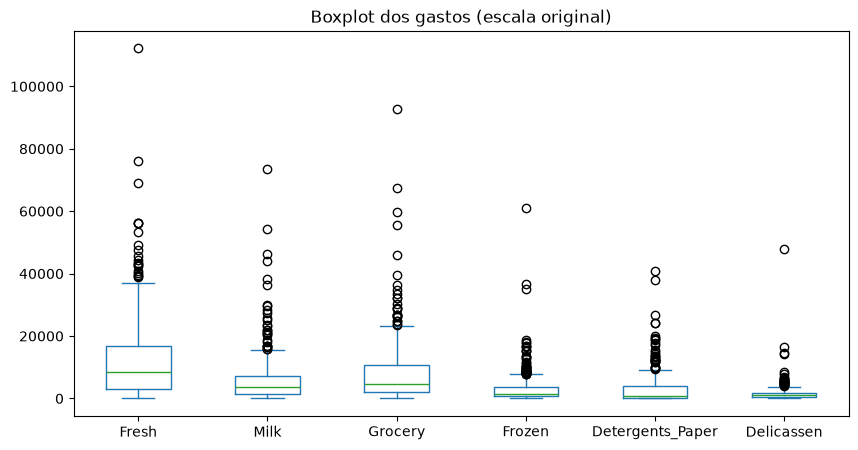

In [5]:
gastos.hist(bins=30, figsize=(12, 7))
plt.tight_layout()
plt.show()

gastos.plot(kind='box', figsize=(10, 5))
plt.title('Boxplot dos gastos (escala original)')
plt.show()

In [ ]:
gastos_log = np.log1p(gastos)         

scaler = StandardScaler()
X = scaler.fit_transform(gastos_log)   

print("Média de cada coluna:", X.mean(axis=0).round(3))
print("Desvio de cada coluna:", X.std(axis=0).round(3))

Média de cada coluna: [ 0. -0. -0.  0. -0. -0.]
Desvio de cada coluna: [1. 1. 1. 1. 1. 1.]


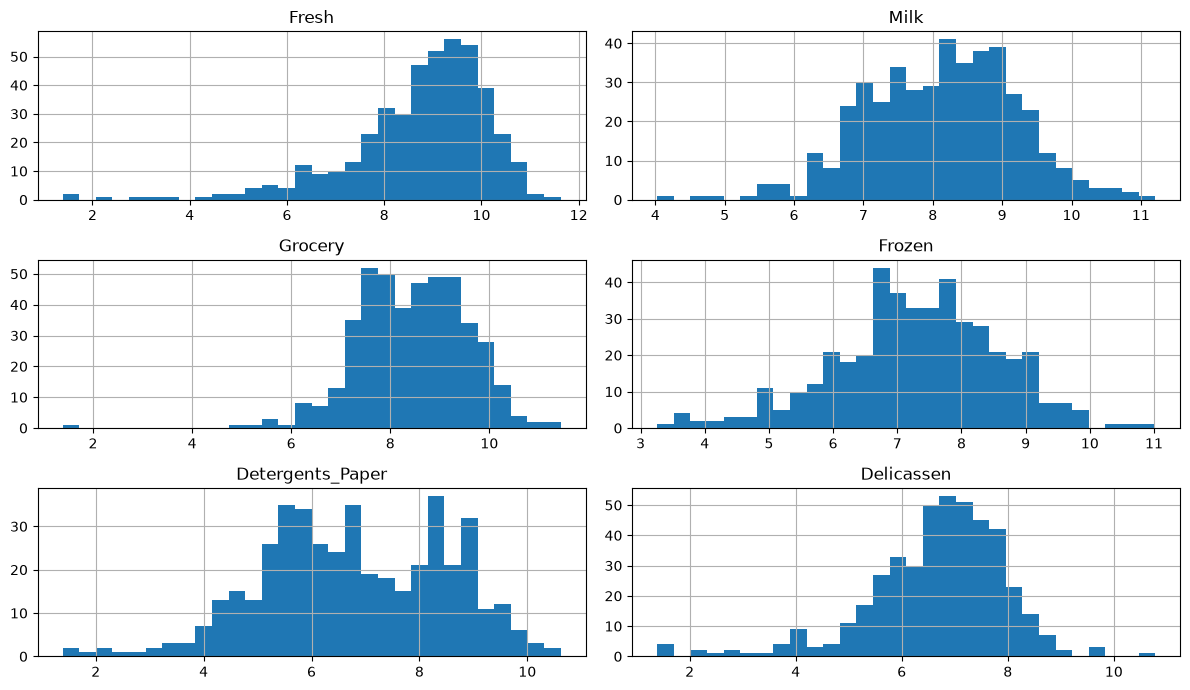

In [7]:
gastos_log.hist(bins=30, figsize=(12, 7))
plt.tight_layout()
plt.show()

In [8]:
corr = gastos_log.corr()
corr.round(2).style.background_gradient(cmap='Blues')

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh,1.000000,-0.020000,-0.130000,0.390000,-0.160000,0.260000
Milk,-0.020000,1.000000,0.760000,-0.060000,0.680000,0.340000
Grocery,-0.130000,0.760000,1.000000,-0.160000,0.800000,0.240000
Frozen,0.390000,-0.060000,-0.160000,1.000000,-0.210000,0.260000
Detergents_Paper,-0.160000,0.680000,0.800000,-0.210000,1.000000,0.170000
Delicassen,0.260000,0.340000,0.240000,0.260000,0.170000,1.000000


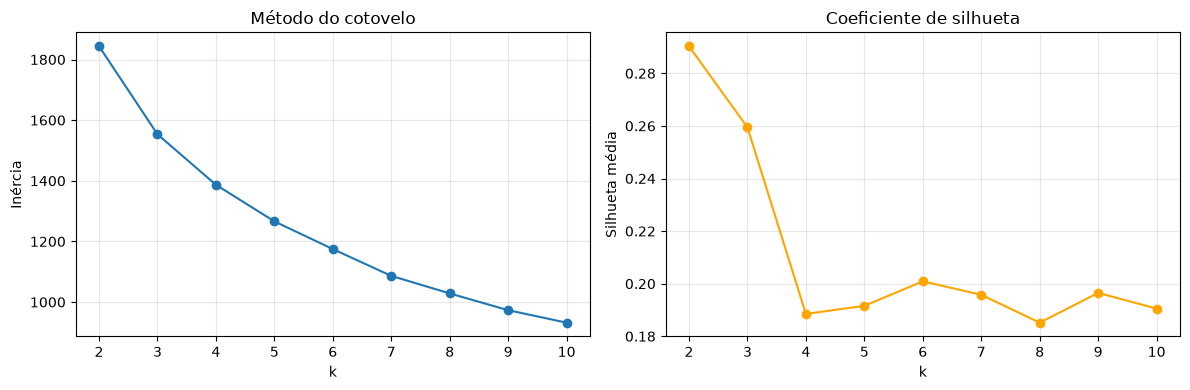

In [9]:
ks = range(2, 11)
inercias = []
silhuetas = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    rotulos_k = km.fit_predict(X)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X, rotulos_k))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

eixos[0].plot(list(ks), inercias, marker='o')
eixos[0].set_xlabel('k')
eixos[0].set_ylabel('Inércia')
eixos[0].set_title('Método do cotovelo')
eixos[0].grid(alpha=0.3)

eixos[1].plot(list(ks), silhuetas, marker='o', color='orange')
eixos[1].set_xlabel('k')
eixos[1].set_ylabel('Silhueta média')
eixos[1].set_title('Coeficiente de silhueta')
eixos[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
k_escolhido = 3   

In [11]:
def rodar_dez(init):
    inercias_finais = []
    for semente in range(10):
        km = KMeans(n_clusters=k_escolhido, init=init, n_init=1, random_state=semente)
        km.fit(X)
        inercias_finais.append(km.inertia_)
    return np.array(inercias_finais)

res_random = rodar_dez('random')
res_pp = rodar_dez('k-means++')

comparacao = pd.DataFrame({
    'random': res_random,
    'k-means++': res_pp
})
print(comparacao.round(4))
print()
print(comparacao.agg(['min', 'max', 'mean', 'std']).round(4))

      random  k-means++
0  1553.3901  1553.7747
1  1553.4458  1553.4458
2  1582.2281  1553.3395
3  1553.7970  1582.2281
4  1553.4458  1582.2281
5  1626.5544  1582.2281
6  1582.1849  1553.7471
7  1553.4458  1580.0258
8  1580.2269  1553.4458
9  1553.4213  1553.4458

         random  k-means++
min   1553.3901  1553.3395
max   1626.5544  1582.2281
mean  1569.2140  1564.7909
std     24.1067    14.5482


In [12]:
km_final = KMeans(n_clusters=k_escolhido, n_init=10, random_state=42)
rotulos = km_final.fit_predict(X)

print(pd.Series(rotulos).value_counts().sort_index())

0     80
1    147
2    213
Name: count, dtype: int64


In [ ]:
centros_padronizados = km_final.cluster_centers_
centros_log = scaler.inverse_transform(centros_padronizados)   # desfaz o Z-score
centros_originais = np.expm1(centros_log)                      # desfaz o log1p

tabela = pd.DataFrame(
    centros_originais,
    columns=gastos.columns,
    index=[f'Grupo {i}' for i in range(k_escolhido)]
).round(0)

tabela

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Grupo 0,1095.0,5635.0,9851.0,344.0,3392.0,318.0
Grupo 1,11287.0,7972.0,10520.0,2168.0,2762.0,1906.0
Grupo 2,7869.0,1529.0,1985.0,1976.0,246.0,602.0


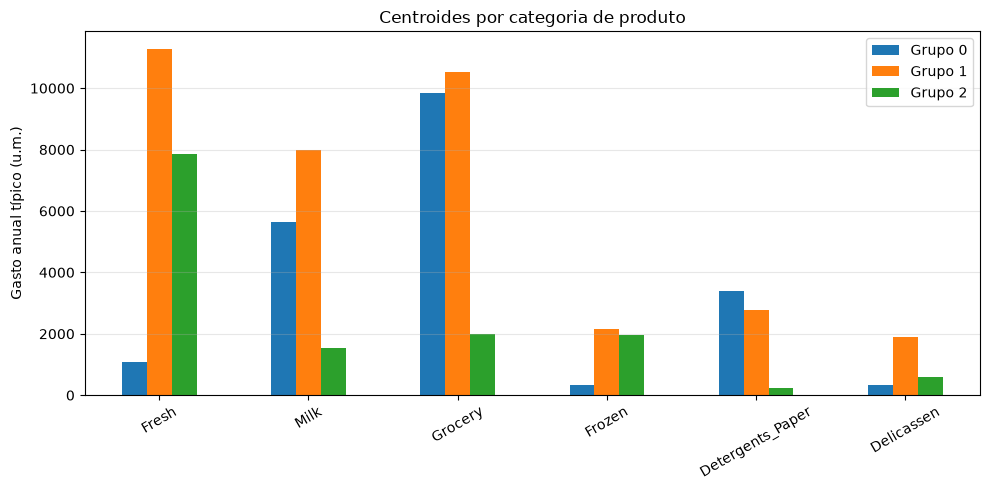

In [14]:
tabela.T.plot(kind='bar', figsize=(10, 5))
plt.ylabel('Gasto anual típico (u.m.)')
plt.title('Centroides por categoria de produto')
plt.xticks(rotation=30)
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [15]:
canal = externos['Channel'].map({1: 'Horeca', 2: 'Retail'})
regiao = externos['Region'].map({1: 'Lisboa', 2: 'Porto', 3: 'Outras'})

print(pd.crosstab(rotulos, canal, rownames=['grupo'], colnames=['Channel']))
print()
print(pd.crosstab(rotulos, regiao, rownames=['grupo'], colnames=['Region']))
print()
ari = adjusted_rand_score(externos['Channel'], rotulos)
print(f"Adjusted Rand Index (grupos x Channel): {ari:.4f}")

Channel  Horeca  Retail
grupo                  
0            32      48
1            56      91
2           210       3

Region  Lisboa  Outras  Porto
grupo                        
0           14      56     10
1           23     113     11
2           40     147     26

Adjusted Rand Index (grupos x Channel): 0.3504


In [16]:
gastos.groupby(externos['Channel']).mean().round(0)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Channel,,,,,,
1,13476.0,3452.0,3962.0,3748.0,791.0,1416.0
2,8904.0,10716.0,16323.0,1653.0,7270.0,1753.0


Variância explicada: [0.441 0.272]


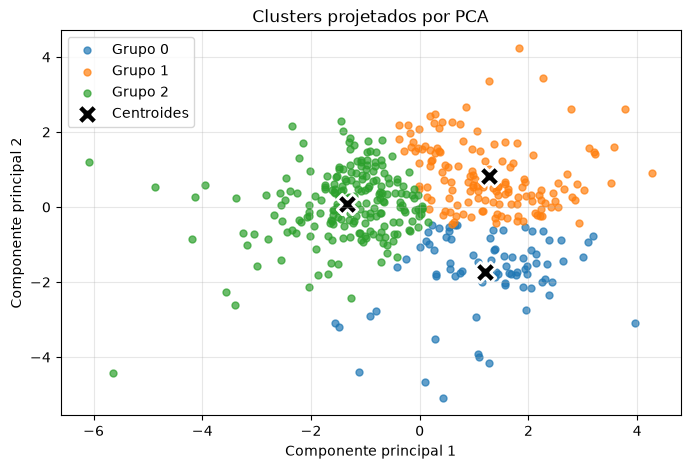

In [17]:
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X)
centros_2d = pca.transform(km_final.cluster_centers_)

print("Variância explicada:", pca.explained_variance_ratio_.round(3))

for g in range(k_escolhido):
    m = rotulos == g
    plt.scatter(X_2d[m, 0], X_2d[m, 1], s=25, alpha=0.7, label=f'Grupo {g}')

plt.scatter(centros_2d[:, 0], centros_2d[:, 1], marker='X', s=220,
            c='black', edgecolors='white', linewidths=2, label='Centroides')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.title('Clusters projetados por PCA')
plt.legend()
plt.grid(alpha=0.3)
plt.show()